## Problem Statement :- To develop a machine learning model that predicts the number of customer orders for a product or service based on historical data.





In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gdown
import warnings
warnings.filterwarnings('ignore')

### 1. Loading Data

In [2]:
file_id = "1Zfp8B6RBEw5641Xd8qPIItk7flxMLoW1"
#file_path = f"https://drive.google.com/uc?export=download&id={file_id}"
gdown.download(f"https://drive.google.com/uc?id={file_id}", "Sales_Data.csv", quiet=False)
df = pd.read_csv(r"Sales_Data.csv")

Downloading...
From: https://drive.google.com/uc?id=1Zfp8B6RBEw5641Xd8qPIItk7flxMLoW1
To: /content/Sales_Data.csv
100%|██████████| 12.8M/12.8M [00:00<00:00, 47.9MB/s]


In [3]:
df

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False
...,...,...,...,...,...
421565,45,98,2012-09-28,508.37,False
421566,45,98,2012-10-05,628.10,False
421567,45,98,2012-10-12,1061.02,False
421568,45,98,2012-10-19,760.01,False


In [4]:
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [5]:
df.shape

(421570, 5)

In [6]:
df.columns

Index(['Store', 'Dept', 'Date', 'Weekly_Sales', 'IsHoliday'], dtype='object')

In [7]:
df.info

<bound method DataFrame.info of         Store  Dept        Date  Weekly_Sales  IsHoliday
0           1     1  2010-02-05      24924.50      False
1           1     1  2010-02-12      46039.49       True
2           1     1  2010-02-19      41595.55      False
3           1     1  2010-02-26      19403.54      False
4           1     1  2010-03-05      21827.90      False
...       ...   ...         ...           ...        ...
421565     45    98  2012-09-28        508.37      False
421566     45    98  2012-10-05        628.10      False
421567     45    98  2012-10-12       1061.02      False
421568     45    98  2012-10-19        760.01      False
421569     45    98  2012-10-26       1076.80      False

[421570 rows x 5 columns]>

### 2. Data Cleaning

In [8]:
df.isna()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
...,...,...,...,...,...
421565,False,False,False,False,False
421566,False,False,False,False,False
421567,False,False,False,False,False
421568,False,False,False,False,False


In [9]:
df.describe()

,Store,Dept,Weekly_Sales
count,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,15981.258123
std,12.785297,30.492054,22711.183519
min,1.000000,1.000000,-4988.940000
25%,11.000000,18.000000,2079.650000
50%,22.000000,37.000000,7612.030000
75%,33.000000,74.000000,20205.852500
max,45.000000,99.000000,693099.360000


In [10]:
#checking how many negtive values of Weekly_Sales exist in the DF
(df['Weekly_Sales']<0).value_counts()

,count
Weekly_Sales,
False,420285
True,1285


Rows with negative Weekly_Sales is removed to eliminate Anomalies

In [11]:
#negative values of Weekly_Sales represents returns or order cancelled so we should remove it
df = df[df['Weekly_Sales'] >= 0]

In [12]:
df

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False
...,...,...,...,...,...
421565,45,98,2012-09-28,508.37,False
421566,45,98,2012-10-05,628.10,False
421567,45,98,2012-10-12,1061.02,False
421568,45,98,2012-10-19,760.01,False


In [13]:
df.shape

(420285, 5)

In [14]:
df['IsHoliday'] = df['IsHoliday'].astype(int)

In [15]:
df

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,0
1,1,1,2010-02-12,46039.49,1
2,1,1,2010-02-19,41595.55,0
3,1,1,2010-02-26,19403.54,0
4,1,1,2010-03-05,21827.90,0
...,...,...,...,...,...
421565,45,98,2012-09-28,508.37,0
421566,45,98,2012-10-05,628.10,0
421567,45,98,2012-10-12,1061.02,0
421568,45,98,2012-10-19,760.01,0


In [16]:
#extracting day,week , month ,year from Date column
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Week'] = df['Date'].dt.isocalendar().week
df['Day'] = df['Date'].dt.day

In [17]:
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Year,Month,Week,Day
0,1,1,2010-02-05,24924.50,0,2010,2,5,5
1,1,1,2010-02-12,46039.49,1,2010,2,6,12
2,1,1,2010-02-19,41595.55,0,2010,2,7,19
3,1,1,2010-02-26,19403.54,0,2010,2,8,26
4,1,1,2010-03-05,21827.90,0,2010,3,9,5


In [18]:
df = df.drop(columns = ['Date'])

EDA - Exploratory Data Analysis

In [19]:
monthly_sales = df.groupby('Month')['Weekly_Sales'].mean()
monthly_sales

,Weekly_Sales
Month,
1,14177.402925
2,16044.626423
3,15462.397412
4,15693.388747
5,15843.753725
6,16394.151442
7,15903.137562
8,16109.142779
9,15145.234221


### 3. Performing EDA

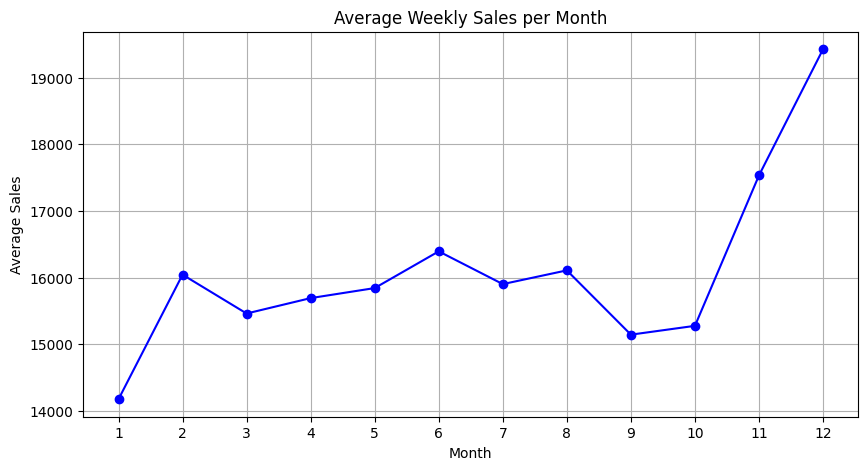

In [20]:
#observing trends between month and average sales
plt.figure(figsize=(10,5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o', color='blue')
plt.title('Average Weekly Sales per Month')
plt.xlabel('Month')
plt.ylabel('Average Sales')
plt.xticks(range(1,13))
plt.grid(True)
plt.show()

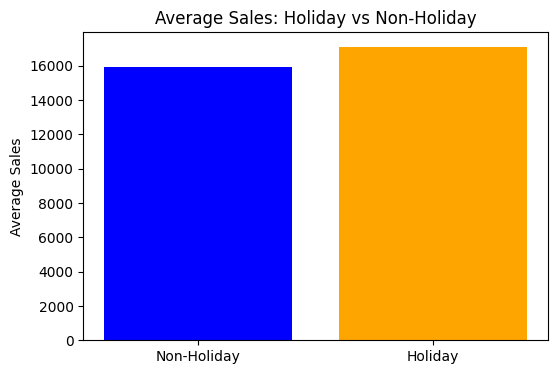

In [21]:
#observing trends between the sales done on Holiday and Non-Holiday
holiday_sales = df.groupby('IsHoliday')['Weekly_Sales'].mean()

plt.figure(figsize=(6,4))
plt.bar(['Non-Holiday', 'Holiday'], holiday_sales.values, color=['blue', 'orange'])
plt.title('Average Sales: Holiday vs Non-Holiday')
plt.ylabel('Average Sales')
plt.show()

In [22]:
df

,Store,Dept,Weekly_Sales,IsHoliday,Year,Month,Week,Day
0,1,1,24924.50,0,2010,2,5,5
1,1,1,46039.49,1,2010,2,6,12
2,1,1,41595.55,0,2010,2,7,19
3,1,1,19403.54,0,2010,2,8,26
4,1,1,21827.90,0,2010,3,9,5
...,...,...,...,...,...,...,...,...
421565,45,98,508.37,0,2012,9,39,28
421566,45,98,628.10,0,2012,10,40,5
421567,45,98,1061.02,0,2012,10,41,12
421568,45,98,760.01,0,2012,10,42,19


TRAINING THE MODEL

In [23]:
X = df[['Store','Dept','IsHoliday','Year','Month','Week','Day']]
Y = df['Weekly_Sales']

### 4. Train-Test split

In [24]:
#TRAIN TEST SPLIT
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)


In [25]:
print("Training size:", X_train.shape)
print("Testing size:", X_test.shape)

Training size: (336228, 7)
Testing size: (84057, 7)


### 5. Trainig the model

#### Model 1 - Linear Regression

In [26]:
#Fit the Data into the LinearRegression Model
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

#print("Model training complete! ✅")

LinearRegression()

In [27]:
#now predicting the values
y_pred = lr_model.predict(X_test)

print("Predicted values (first 5):", y_pred[:5])
print("Actual values (first 5):", y_test[:5].values)

Predicted values (first 5): [ 8894.89864929  8189.13956774 11510.00426332 18855.69315115
 18244.7525735 ]
Actual values (first 5): [17285.76   693.91 15210.2  20505.68   220.  ]


In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print("MAE : ",mae)
print("RMSE : ",rmse)
print("R2 Score : ",r2)

MAE :  15157.305315246367
RMSE :  22494.703780404005
R2 Score :  0.029986037366971363


#### Model 2 . Random Forest Regression

In [29]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)


RandomForestRegressor(random_state=42)

In [30]:
#Evaluating the result
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_pred_rf = rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)
print("MAE : ",mae_rf)
print("RMSE : ",rmse_rf)
print("R2 Score : ",r2_rf)

MAE :  1372.8320641457583
RMSE :  3676.9191813452176
R2 Score :  0.9740829481912558


#### Model 3. XGBoost

In [31]:
!pip install xgboost

In [32]:
from xgboost import XGBRegressor
xgb_model = XGBRegressor(n_estimators=500 , learning_rate=0.3, random_state=42)
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.3, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [33]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_pred_xgb = xgb_model.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)
print("MAE : ",mae_xgb)
print("RMSE : ",rmse_xgb)
print("R2 Score : ",r2_xgb)

MAE :  2174.7839183086185
RMSE :  4120.084273729505
R2 Score :  0.9674590949842085


### 6. Evaluating the model

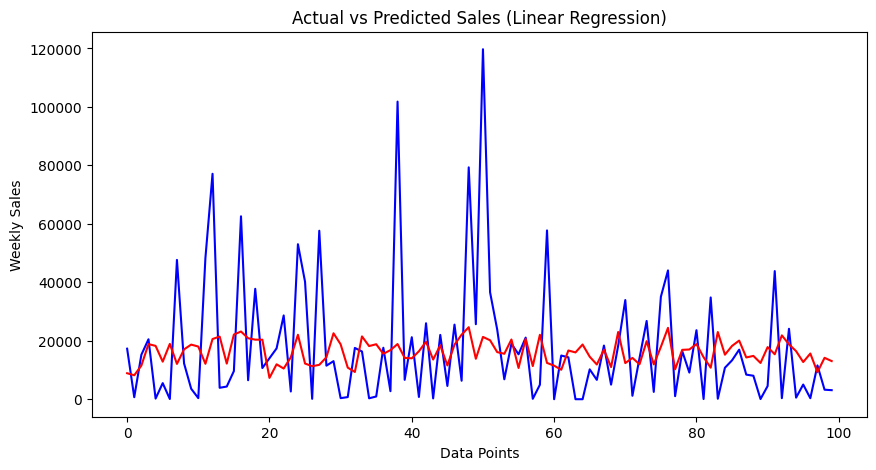

In [34]:
#Actual Vs Predicted graph
plt.figure(figsize=(10,5))
plt.plot(y_test[:100].values, color='blue')
plt.plot(y_pred[:100], color='red')
plt.title('Actual vs Predicted Sales (Linear Regression)')
plt.xlabel('Data Points')
plt.ylabel('Weekly Sales')
plt.show()

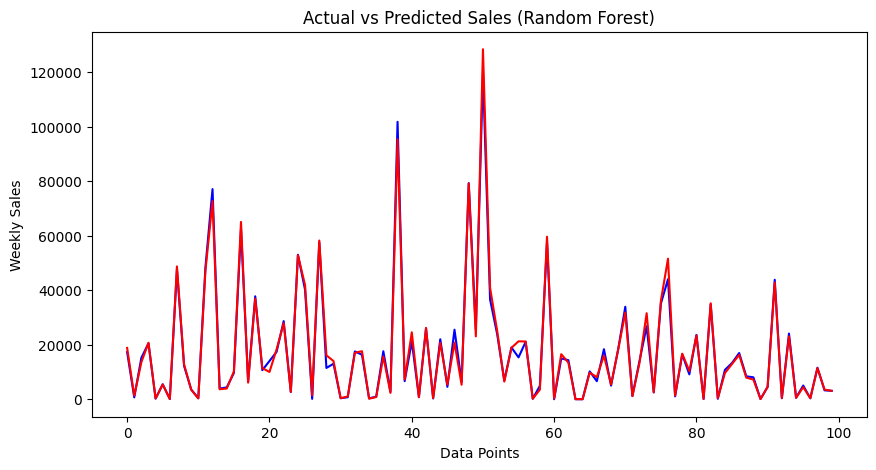

In [35]:
#Actual Vs Predicted graph
plt.figure(figsize=(10,5))
plt.plot(y_test[:100].values, color='blue')
plt.plot(y_pred_rf[:100], color='red')
plt.title('Actual vs Predicted Sales (Random Forest)')
plt.xlabel('Data Points')
plt.ylabel('Weekly Sales')
plt.show()

Taking Prediction from the Model

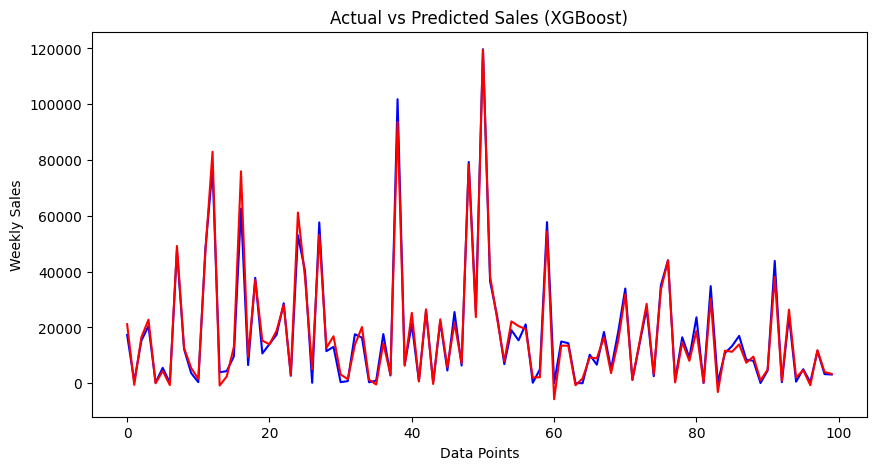

In [36]:
#Actual Vs Predicted graph
plt.figure(figsize=(10,5))
plt.plot(y_test[:100].values, color='blue')
plt.plot(y_pred_xgb[:100], color='red')
plt.title('Actual vs Predicted Sales (XGBoost)')
plt.xlabel('Data Points')
plt.ylabel('Weekly Sales')
plt.show()

In [37]:
df.loc[20000]  #given this data as input

,20000
Store,2.0
Dept,95.0
Weekly_Sales,151758.6
IsHoliday,0.0
Year,2012.0
Month,8.0
Week,33.0
Day,17.0


In [38]:
#giving input to the model
newData = pd.DataFrame({
    'Store' : [2],
    'Dept' : [95],
    'IsHoliday' : [0],
    'Year' : [2012],
    'Month' : [8],
    'Week' : [33],
    'Day' : [17]
})

In [39]:
prediction = rf_model.predict(newData)
print("Predicted Sales",prediction)

Predicted Sales [150456.2718]


In [40]:
prediction = xgb_model.predict(newData)
print(prediction)

[152203.]
